### Hr Attriction Prediction and Analysis Using Linear Regression (Binary Classification)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [ ]:
Data = pd.read_csv('HR_Data.csv')
Data.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [ ]:
#checking my dataset for null values and incorrect formating
Data.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


In [ ]:
#Checking the correlation between each field and employee attrition:
Data.corr(numeric_only=True)['left'].sort_values(ascending=False)

left                     1.000000
time_spend_company       0.144822
average_montly_hours     0.071287
number_project           0.023787
last_evaluation          0.006567
promotion_last_5years   -0.061788
Work_accident           -0.154622
satisfaction_level      -0.388375
Name: left, dtype: float64

The result from the correlation analysis shows that the most significant relationship is between employee attrition and satisafction level, but this is not necesarily right as the correlation function might have missed non linear relation between attrition rate  and other variables. 

In [ ]:
#Comparing the averages for employees who stayed versus employees who left:
Data.groupby('left')[
    [
        'satisfaction_level',
        'last_evaluation',
        'number_project',
        'average_montly_hours',
        'time_spend_company',
        'Work_accident',
        'promotion_last_5years'
    ]
].mean()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years
left,,,,,,,
0,0.666810,0.715473,3.786664,199.060203,3.380032,0.175009,0.026251
1,0.440098,0.718113,3.855503,207.419210,3.876505,0.047326,0.005321


Once agains the most significant difference is shown in the satisfaction level of employees, promotion in the last five years also shows a significant relationship, other somewhat important relationships are average mothly hours, as they are slightly higher in employees that left, work accident is also somewhat significant.

**exploring my non-numeric dataset relationship with attrition.**

In [ ]:
Data.groupby('Department')['left'].mean().sort_values(ascending=False)

Department
hr             0.290934
accounting     0.265971
technical      0.256250
support        0.248991
sales          0.244928
marketing      0.236597
IT             0.222494
product_mng    0.219512
RandD          0.153748
management     0.144444
Name: left, dtype: float64

<Axes: xlabel='Department'>

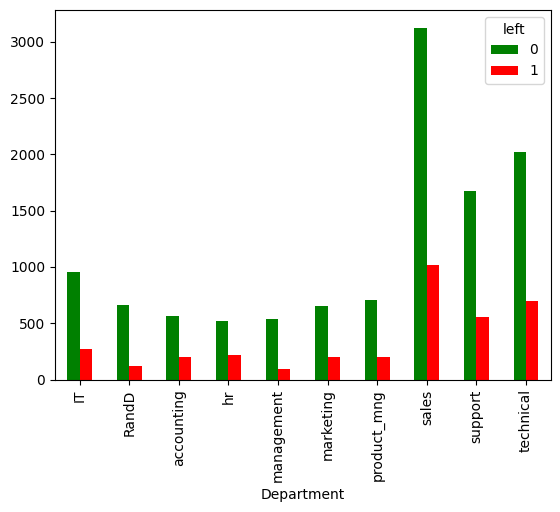

In [ ]:
#visualizing the rate of attrition per department
pd.crosstab(Data.Department, Data.left).plot(kind = 'bar', color= ['green', 'red'])

The attrition rates across most departments are relatively similar, with no major differences that strongly distinguish one department from another. Because the variation is limited, I will exclude the Department feature from the initial analysis and model for now. Once the baseline model has been trained and evaluated, I will encode the department data and add it as an additional feature. I can then compare the model’s performance before and after including Department to determine whether it provides meaningful predictive value for employee attrition.

In [ ]:
Data.groupby('salary')['left'].mean().sort_values(ascending=False)

salary
low       0.296884
medium    0.204313
high      0.066289
Name: left, dtype: float64

<Axes: xlabel='salary'>

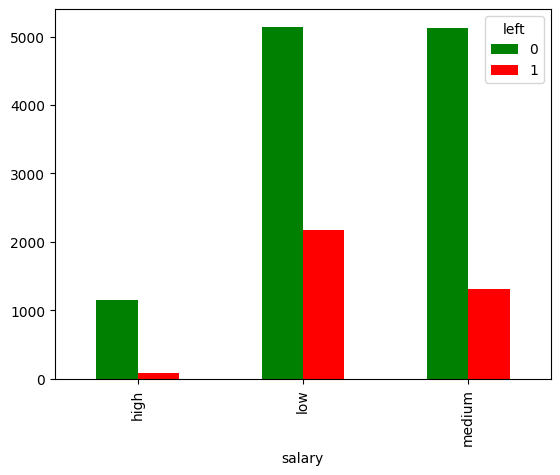

In [ ]:
#Visualizing attrition rate in the different salary ranges
pd.crosstab(Data.salary, Data.left).plot(kind= 'bar', color=['green', 'red'])

Salary differences shows a significant relationship wit attrition rate as we see that we have more people earning low and medium range salary leaving compared to the high earners


**Building my predictive model**

In [ ]:
#Creating a dataframe with just the fields i need for X (independent) variables
Data1 = Data[['satisfaction_level', 'promotion_last_5years', 'average_montly_hours', 'Work_accident', 'salary', 'Department']]
Data1

,satisfaction_level,promotion_last_5years,average_montly_hours,Work_accident,salary,Department
0,0.38,0,157,0,low,sales
1,0.80,0,262,0,medium,sales
2,0.11,0,272,0,medium,sales
3,0.72,0,223,0,low,sales
4,0.37,0,159,0,low,sales
...,...,...,...,...,...,...
14994,0.40,0,151,0,low,support
14995,0.37,0,160,0,low,support
14996,0.37,0,143,0,low,support
14997,0.11,0,280,0,low,support


In [ ]:
#Creating dummy variable for my salary field
dummies = pd.get_dummies(Data1[['salary', 'Department']], drop_first=True, dtype = int)
dummies

,salary_low,salary_medium,Department_RandD,Department_accounting,Department_hr,Department_management,Department_marketing,Department_product_mng,Department_sales,Department_support,Department_technical
0,1,0,0,0,0,0,0,0,1,0,0
1,0,1,0,0,0,0,0,0,1,0,0
2,0,1,0,0,0,0,0,0,1,0,0
3,1,0,0,0,0,0,0,0,1,0,0
4,1,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...
14994,1,0,0,0,0,0,0,0,0,1,0
14995,1,0,0,0,0,0,0,0,0,1,0
14996,1,0,0,0,0,0,0,0,0,1,0
14997,1,0,0,0,0,0,0,0,0,1,0


In [ ]:
#adding dummy data to our dataset
Data1 = pd.concat([Data1, dummies], axis='columns')
#dropping salary column
Data1.drop(columns = ['salary', 'Department'], inplace = True)
Data1

,satisfaction_level,promotion_last_5years,average_montly_hours,Work_accident,salary_low,salary_medium,Department_RandD,Department_accounting,Department_hr,Department_management,Department_marketing,Department_product_mng,Department_sales,Department_support,Department_technical
0,0.38,0,157,0,1,0,0,0,0,0,0,0,1,0,0
1,0.80,0,262,0,0,1,0,0,0,0,0,0,1,0,0
2,0.11,0,272,0,0,1,0,0,0,0,0,0,1,0,0
3,0.72,0,223,0,1,0,0,0,0,0,0,0,1,0,0
4,0.37,0,159,0,1,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0,151,0,1,0,0,0,0,0,0,0,0,1,0
14995,0.37,0,160,0,1,0,0,0,0,0,0,0,0,1,0
14996,0.37,0,143,0,1,0,0,0,0,0,0,0,0,1,0
14997,0.11,0,280,0,1,0,0,0,0,0,0,0,0,1,0


In [ ]:
#Assigning all our independent variable to the X variable
X = Data1
X

,satisfaction_level,promotion_last_5years,average_montly_hours,Work_accident,salary_low,salary_medium,Department_RandD,Department_accounting,Department_hr,Department_management,Department_marketing,Department_product_mng,Department_sales,Department_support,Department_technical
0,0.38,0,157,0,1,0,0,0,0,0,0,0,1,0,0
1,0.80,0,262,0,0,1,0,0,0,0,0,0,1,0,0
2,0.11,0,272,0,0,1,0,0,0,0,0,0,1,0,0
3,0.72,0,223,0,1,0,0,0,0,0,0,0,1,0,0
4,0.37,0,159,0,1,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0,151,0,1,0,0,0,0,0,0,0,0,1,0
14995,0.37,0,160,0,1,0,0,0,0,0,0,0,0,1,0
14996,0.37,0,143,0,1,0,0,0,0,0,0,0,0,1,0
14997,0.11,0,280,0,1,0,0,0,0,0,0,0,0,1,0


In [ ]:
#Assigning our dependent variable to Y
Y = Data.left
Y

0        1
1        1
2        1
3        1
4        1
        ..
14994    1
14995    1
14996    1
14997    1
14998    1
Name: left, Length: 14999, dtype: int64

In [ ]:
#splitting the data into train and test dataset 
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2,random_state=42)

In [ ]:
#Training my Model
#increase max iterations to 1000 instead of the default 100 because we have created more variables by adding department to our model
attrition_model = LogisticRegression(max_iter=1000)

In [ ]:
attrition_model.fit(x_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [ ]:
attrition_model.predict(x_test)


array([0, 0, 0, ..., 0, 0, 1], shape=(3000,))

In [ ]:
attrition_model.score(x_test, y_test)

0.772

In [ ]:
from sklearn.metrics import accuracy_score

y_predicted = attrition_model.predict(x_test)

print("Model accuracy:", accuracy_score(y_test, y_predicted))

print("\nClass balance:")
print(y_test.value_counts(normalize=True))

Model accuracy: 0.772

Class balance:
left
0    0.764667
1    0.235333
Name: proportion, dtype: float64


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_predicted)

print(cm)

[[2148  146]
 [ 538  168]]


Several combinations of independent variables were tested using Logistic Regression. The highest accuracy achieved was approximately 77.2% using satisfaction level, promotion history, average monthly hours, work accident, salary, and department.

Including Department produced a small improvement in overall accuracy compared with similar models that excluded it, suggesting that Department contributes some predictive information.

However, the confusion matrices show that the model still identifies only a small proportion of employees who actually leave. Therefore, although accuracy improved slightly across some feature combinations, overall accuracy alone is not sufficient to evaluate the model's effectiveness for employee attrition prediction.

### improving my model
the exploratory analysis below will be used for model improvement later

In [ ]:
Data.groupby('time_spend_company')['left'].mean()

time_spend_company
2     0.016338
3     0.246159
4     0.348064
5     0.565513
6     0.291086
7     0.000000
8     0.000000
10    0.000000
Name: left, dtype: float64

In [ ]:
Data.groupby('number_project')['left'].mean()

number_project
2    0.656198
3    0.017756
4    0.093700
5    0.221659
6    0.557922
7    1.000000
Name: left, dtype: float64

In [ ]:
Data.groupby('number_project')['left'].agg(
    ['mean', 'count', 'sum']
)

,mean,count,sum
number_project,,,
2,0.656198,2388,1567
3,0.017756,4055,72
4,0.093700,4365,409
5,0.221659,2761,612
6,0.557922,1174,655
7,1.000000,256,256


In [ ]:
Data.groupby('time_spend_company')['left'].agg(
    ['mean', 'count', 'sum']
)

,mean,count,sum
time_spend_company,,,
2,0.016338,3244,53
3,0.246159,6443,1586
4,0.348064,2557,890
5,0.565513,1473,833
6,0.291086,718,209
7,0.000000,188,0
8,0.000000,162,0
10,0.000000,214,0
